Install & imports

In [1]:
!pip -q install requests pandas scikit-learn matplotlib seaborn

import requests, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             classification_report, confusion_matrix,
                             f1_score, roc_auc_score)

Data download (Sylhet, 2000-2025)

In [2]:
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 24.8949, "longitude": 91.8687,
    "start_date": "2000-01-01", "end_date": "2025-12-31",
    "daily": ["precipitation_sum","temperature_2m_mean","temperature_2m_max",
              "temperature_2m_min","relative_humidity_2m_mean",
              "pressure_msl_mean","wind_speed_10m_max","cloud_cover_mean"],
    "timezone": "Asia/Dhaka"
}
r = requests.get(url, params=params, timeout=120)
r.raise_for_status()
df = pd.DataFrame(r.json()["daily"])
df["time"] = pd.to_datetime(df["time"])
df = df.set_index("time").rename(columns={"precipitation_sum":"rain"})
df.to_csv("sylhet_weather_2000_2025.csv")
print(df.shape); df.head()

(9497, 8)


,rain,temperature_2m_mean,temperature_2m_max,temperature_2m_min,relative_humidity_2m_mean,pressure_msl_mean,wind_speed_10m_max,cloud_cover_mean
time,,,,,,,,
2000-01-01,0.0,17.8,25.1,10.5,69,1015.0,7.7,0
2000-01-02,0.0,18.0,25.4,10.7,68,1014.3,7.2,0
2000-01-03,0.0,17.8,24.9,10.2,71,1013.0,6.9,0
2000-01-04,0.0,17.3,24.8,10.9,71,1013.4,8.7,6
2000-01-05,0.0,16.8,24.4,9.6,74,1013.8,7.5,11


EDA

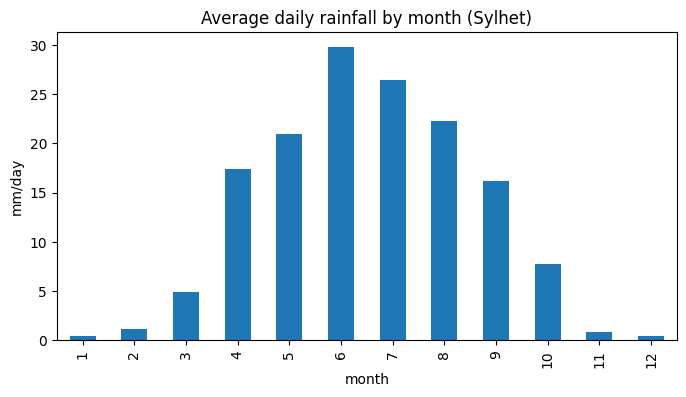

Missing values:
 rain                         0
temperature_2m_mean          0
temperature_2m_max           0
temperature_2m_min           0
relative_humidity_2m_mean    0
pressure_msl_mean            0
wind_speed_10m_max           0
cloud_cover_mean             0
month                        0
dtype: int64
Rainy days (>=1mm) %: 54.30135832368116
Heavy rain days (>=50mm) count: 520


In [3]:
df["month"] = df.index.month
monthly = df.groupby("month")["rain"].mean()
monthly.plot(kind="bar", figsize=(8,4), title="Average daily rainfall by month (Sylhet)")
plt.ylabel("mm/day"); plt.show()

print("Missing values:\n", df.isna().sum())
print("Rainy days (>=1mm) %:", (df["rain"]>=1).mean()*100)
print("Heavy rain days (>=50mm) count:", (df["rain"]>=50).sum())

Feature engineering (leakage chhara)

In [4]:
d = df.drop(columns=["month"]).copy()
base_cols = [c for c in d.columns]

feat = pd.DataFrame(index=d.index)
for c in base_cols:
    for lag in [1,2,3]:
        feat[f"{c}_lag{lag}"] = d[c].shift(lag-1)   # lag1 = today's value
feat["rain_sum_3d"]  = d["rain"].rolling(3).sum()
feat["rain_sum_7d"]  = d["rain"].rolling(7).sum()
feat["rain_sum_14d"] = d["rain"].rolling(14).sum()
feat["rain_sum_30d"] = d["rain"].rolling(30).sum()
feat["pressure_change_1d"] = d["pressure_msl_mean"].diff()
doy = d.index.dayofyear
feat["doy_sin"] = np.sin(2*np.pi*doy/365.25)
feat["doy_cos"] = np.cos(2*np.pi*doy/365.25)

# Targets: tomorrow
feat["y_rain_mm"]  = d["rain"].shift(-1)
feat["y_heavy"]    = (d["rain"].shift(-1) >= 20).astype(int)   # heavy rain >=20 mm
feat = feat.dropna()
print(feat.shape, "Heavy rain share:", feat["y_heavy"].mean().round(3))

(9467, 33) Heavy rain share: 0.219


Time-based spli

In [5]:
train = feat.loc[:"2017-12-31"]
val   = feat.loc["2018-01-01":"2021-12-31"]
test  = feat.loc["2022-01-01":]

X_cols = [c for c in feat.columns if not c.startswith("y_")]
Xtr, Xva, Xte = train[X_cols], val[X_cols], test[X_cols]
print(len(train), len(val), len(test))

6546 1461 1460


Task A, Heavy rain classification (>=20 mm)

In [7]:
ytr, yva, yte = train["y_heavy"], val["y_heavy"], test["y_heavy"]

# Baseline: persistence (aj heavy hole kal heavy)
base_pred = (test["rain_lag1"] >= 20).astype(int)
print("Persistence baseline F1:", round(f1_score(yte, base_pred), 3))

lr = LogisticRegression(max_iter=2000, class_weight="balanced")
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(Xtr)
lr.fit(sc.transform(Xtr), ytr)

rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=42)
rf.fit(Xtr, ytr)

for name, model, Xt in [("LogReg", lr, sc.transform(Xte)), ("RandomForest", rf, Xte)]:
    p = model.predict_proba(Xt)[:,1]
    pred = (p >= 0.5).astype(int)
    print(f"\n{name}: F1={f1_score(yte,pred):.3f}  ROC-AUC={roc_auc_score(yte,p):.3f}")
    print(classification_report(yte, pred, digits=3))

Persistence baseline F1: 0.584

LogReg: F1=0.624  ROC-AUC=0.897
              precision    recall  f1-score   support

           0      0.963     0.747     0.841      1157
           1      0.480     0.891     0.624       303

    accuracy                          0.777      1460
   macro avg      0.721     0.819     0.732      1460
weighted avg      0.863     0.777     0.796      1460


RandomForest: F1=0.608  ROC-AUC=0.892
              precision    recall  f1-score   support

           0      0.897     0.898     0.898      1157
           1      0.609     0.607     0.608       303

    accuracy                          0.838      1460
   macro avg      0.753     0.753     0.753      1460
weighted avg      0.837     0.838     0.838      1460



Threshold tuning

Best threshold (from validation): 0.426
Test F1: 0.633
              precision    recall  f1-score   support

           0      0.924     0.848     0.884      1157
           1      0.558     0.733     0.633       303

    accuracy                          0.824      1460
   macro avg      0.741     0.790     0.759      1460
weighted avg      0.848     0.824     0.832      1460



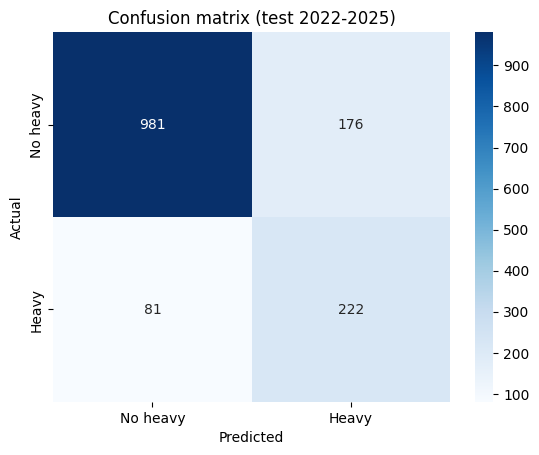

In [8]:
from sklearn.metrics import precision_recall_curve
import seaborn as sns

pv = rf.predict_proba(Xva)[:, 1]
prec, rec, thr = precision_recall_curve(yva, pv)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[np.argmax(f1s[:-1])]
print("Best threshold (from validation):", round(float(best_thr), 3))

pt = rf.predict_proba(Xte)[:, 1]
pred = (pt >= best_thr).astype(int)
print("Test F1:", round(f1_score(yte, pred), 3))
print(classification_report(yte, pred, digits=3))

cm = confusion_matrix(yte, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No heavy", "Heavy"], yticklabels=["No heavy", "Heavy"])
plt.title("Confusion matrix (test 2022-2025)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

Task B, Rainfall amount regression

In [9]:
rfr = RandomForestRegressor(n_estimators=400, min_samples_leaf=3, n_jobs=-1, random_state=42)
rfr.fit(Xtr, train["y_rain_mm"])
pr = rfr.predict(Xte)

naive = test["rain_lag1"]                                # persistence
clim = np.full(len(test), train["y_rain_mm"].mean())     # train mean

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

for n, p in [("Persistence", naive), ("Train mean", clim), ("RandomForest", pr)]:
    print(f"{n:13s} MAE={mean_absolute_error(test['y_rain_mm'], p):.2f}  "
          f"RMSE={rmse(test['y_rain_mm'], p):.2f}")

Persistence   MAE=7.78  RMSE=14.93
Train mean    MAE=13.77  RMSE=18.27
RandomForest  MAE=8.21  RMSE=13.54


Feature importance

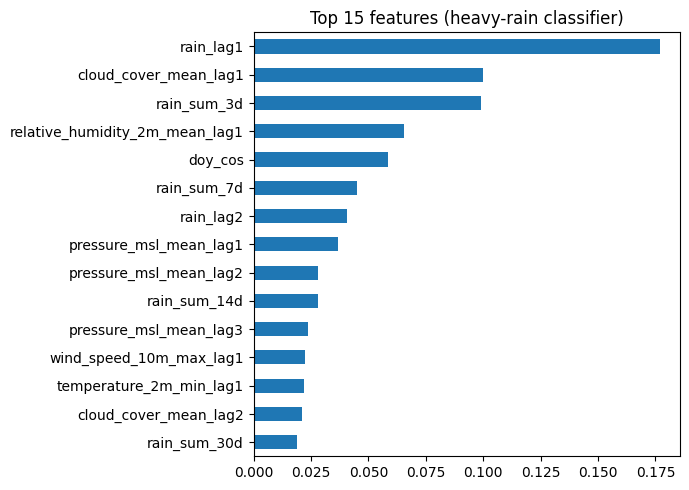

In [10]:
import os
os.makedirs("outputs", exist_ok=True)

imp = pd.Series(rf.feature_importances_, index=X_cols).sort_values(ascending=False).head(15)
plt.figure(figsize=(7, 5))
imp[::-1].plot(kind="barh", title="Top 15 features (heavy-rain classifier)")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

Model, results ar confusion matrix save

In [11]:
import joblib, json

joblib.dump(rf, "outputs/rf_heavy_rain.joblib")

results = {
    "data": "Open-Meteo ERA5 reanalysis, Sylhet, 2000-2025",
    "split": {"train": "2000-2017", "val": "2018-2021", "test": "2022-2025"},
    "heavy_rain_threshold_mm": 20,
    "tuned_probability_threshold": round(float(best_thr), 3),
    "test_f1_rf": round(float(f1_score(yte, pred)), 3),
    "test_roc_auc_rf": round(float(roc_auc_score(yte, pt)), 3),
    "test_f1_persistence_baseline": round(float(f1_score(yte, base_pred)), 3),
    "regression_mae_rf": round(float(mean_absolute_error(test["y_rain_mm"], pr)), 2),
    "regression_rmse_rf": round(float(rmse(test["y_rain_mm"], pr)), 2),
}
with open("outputs/results.json", "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

{
  "data": "Open-Meteo ERA5 reanalysis, Sylhet, 2000-2025",
  "split": {
    "train": "2000-2017",
    "val": "2018-2021",
    "test": "2022-2025"
  },
  "heavy_rain_threshold_mm": 20,
  "tuned_probability_threshold": 0.426,
  "test_f1_rf": 0.633,
  "test_roc_auc_rf": 0.892,
  "test_f1_persistence_baseline": 0.584,
  "regression_mae_rf": 8.21,
  "regression_rmse_rf": 13.54
}


Lead time experiment

In [12]:
def eval_horizon(h):
    y_raw = d["rain"].shift(-h).reindex(feat.index)
    ok = y_raw.notna()
    y = (y_raw >= 20).astype(int)
    Xh, yh = feat.loc[ok, X_cols], y[ok]
    tr, va, te = (Xh.index <= "2017-12-31"), ((Xh.index >= "2018-01-01") & (Xh.index <= "2021-12-31")), (Xh.index >= "2022-01-01")
    m = RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                               class_weight="balanced_subsample", n_jobs=-1, random_state=42)
    m.fit(Xh[tr], yh[tr])
    pv = m.predict_proba(Xh[va])[:, 1]
    pr_, rc_, th_ = precision_recall_curve(yh[va], pv)
    thr_ = th_[np.argmax((2*pr_*rc_/(pr_+rc_+1e-9))[:-1])]
    pt = m.predict_proba(Xh[te])[:, 1]
    pd_ = (pt >= thr_).astype(int)
    from sklearn.metrics import precision_score, recall_score
    return {"lead_days": h, "F1": round(f1_score(yh[te], pd_), 3),
            "precision": round(precision_score(yh[te], pd_), 3),
            "recall": round(recall_score(yh[te], pd_), 3),
            "ROC_AUC": round(roc_auc_score(yh[te], pt), 3)}

lead_df = pd.DataFrame([eval_horizon(h) for h in [1, 2, 3]])
print(lead_df)
lead_df.to_csv("outputs/lead_time_results.csv", index=False)

   lead_days     F1  precision  recall  ROC_AUC
0          1  0.633      0.558   0.733    0.892
1          2  0.578      0.514   0.660    0.851
2          3  0.558      0.434   0.782    0.832


Monsoon vs non-monsoon ar year-wise performance

In [13]:
tdf = test.copy()
tdf["pred"] = pred
tdf["month"] = tdf.index.month
tdf["season"] = np.where(tdf["month"].between(6, 9), "Monsoon (Jun-Sep)", "Other months")

rows = []
for s, g in tdf.groupby("season"):
    rows.append({"group": s, "days": len(g), "heavy_days": int(g["y_heavy"].sum()),
                 "F1": round(f1_score(g["y_heavy"], g["pred"]), 3)})
for y, g in tdf.groupby(tdf.index.year):
    rows.append({"group": str(y), "days": len(g), "heavy_days": int(g["y_heavy"].sum()),
                 "F1": round(f1_score(g["y_heavy"], g["pred"]), 3)})
print(pd.DataFrame(rows))

               group  days  heavy_days     F1
0  Monsoon (Jun-Sep)   488         225  0.691
1       Other months   972          78  0.460
2               2022   365          78  0.649
3               2023   365          77  0.639
4               2024   366          68  0.599
5               2025   364          80  0.644


Model comparison (Gradient Boosting add

In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                     class_weight="balanced", random_state=42)
hgb.fit(Xtr, ytr)

def tuned_eval(model, name):
    pv = model.predict_proba(Xva)[:, 1]
    p_, r_, t_ = precision_recall_curve(yva, pv)
    thr_ = t_[np.argmax((2*p_*r_/(p_+r_+1e-9))[:-1])]
    pt = model.predict_proba(Xte)[:, 1]
    pd_ = (pt >= thr_).astype(int)
    from sklearn.metrics import precision_score, recall_score
    return {"model": name, "val_threshold": round(float(thr_), 3),
            "F1": round(f1_score(yte, pd_), 3),
            "precision": round(precision_score(yte, pd_), 3),
            "recall": round(recall_score(yte, pd_), 3),
            "ROC_AUC": round(roc_auc_score(yte, pt), 3)}

lr_wrap = type("W", (), {"predict_proba": lambda s, X: lr.predict_proba(sc.transform(X))})()
cmp_df = pd.DataFrame([tuned_eval(lr_wrap, "LogReg"),
                       tuned_eval(rf, "RandomForest"),
                       tuned_eval(hgb, "HistGradientBoosting")])
print(cmp_df)
cmp_df.to_csv("outputs/model_comparison.csv", index=False)

                  model  val_threshold     F1  precision  recall  ROC_AUC
0                LogReg          0.824  0.579      0.646   0.525    0.897
1          RandomForest          0.426  0.633      0.558   0.733    0.892
2  HistGradientBoosting          0.565  0.597      0.561   0.637    0.892


Probability calibration

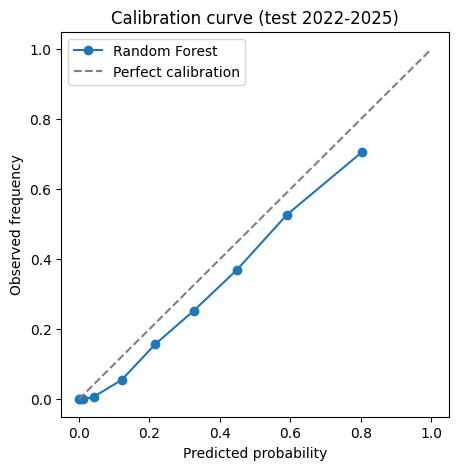

In [15]:
from sklearn.calibration import calibration_curve
pt_rf = rf.predict_proba(Xte)[:, 1]
frac_pos, mean_pred = calibration_curve(yte, pt_rf, n_bins=10, strategy="quantile")

plt.figure(figsize=(5, 5))
plt.plot(mean_pred, frac_pos, "o-", label="Random Forest")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.xlabel("Predicted probability"); plt.ylabel("Observed frequency")
plt.title("Calibration curve (test 2022-2025)"); plt.legend()
plt.savefig("outputs/calibration.png", dpi=200, bbox_inches="tight")
plt.show()

Calibration fix

Brier raw       : 0.1092
Brier calibrated: 0.112


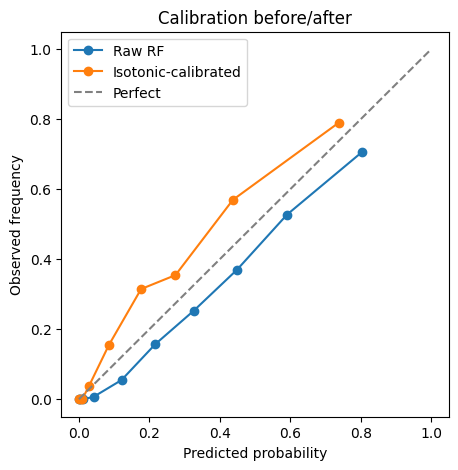

In [16]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

pv_rf = rf.predict_proba(Xva)[:, 1]
iso = IsotonicRegression(out_of_bounds="clip").fit(pv_rf, yva)
pt_raw = rf.predict_proba(Xte)[:, 1]
pt_cal = iso.predict(pt_raw)

print("Brier raw       :", round(brier_score_loss(yte, pt_raw), 4))
print("Brier calibrated:", round(brier_score_loss(yte, pt_cal), 4))

plt.figure(figsize=(5, 5))
for p, lab in [(pt_raw, "Raw RF"), (pt_cal, "Isotonic-calibrated")]:
    fp, mp = calibration_curve(yte, p, n_bins=10, strategy="quantile")
    plt.plot(mp, fp, "o-", label=lab)
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect")
plt.xlabel("Predicted probability"); plt.ylabel("Observed frequency")
plt.title("Calibration before/after"); plt.legend()
plt.savefig("outputs/calibration_after.png", dpi=200, bbox_inches="tight")
plt.show()

F1 er confidence interval (30-din block bootstrap)

In [17]:
rng = np.random.default_rng(42)
y_arr, p_arr = yte.values, pred
n, block = len(y_arr), 30
nb = int(np.ceil(n / block))

f1_boot = []
for _ in range(1000):
    starts = rng.integers(0, n - block + 1, nb)
    idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
    f1_boot.append(f1_score(y_arr[idx], p_arr[idx]))

lo, hi = np.percentile(f1_boot, [2.5, 97.5])
print(f"RF test F1 = {f1_score(y_arr, p_arr):.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")

RF test F1 = 0.633, 95% CI [0.559, 0.692]
